# Grupa C – Random Forest

Las losowy to wiele drzew decyzyjnych, które wspólnie podejmują decyzję. Sprawdźcie, czy las radzi sobie lepiej niż pojedyncze drzewo, dlaczego trudniej zrozumieć jego decyzje oraz jak na wynik wpływają liczba danych, liczba drzew i wybór cech.

`y = yes` oznacza założenie lokaty. `duration` jest wyłączone, bo przed rozmową nie jest znane.

In [ ]:
# Uruchom tę komórkę jako pierwszą – także po każdym restarcie środowiska wykonawczego.
# W Colabie pobiera (albo aktualizuje) repozytorium z GitHuba, lokalnie używa plików z dysku.
import subprocess
import sys
from pathlib import Path

PROJECT = "02_ml_bank_marketing_colab"

if "google.colab" in sys.modules:
    repo_dir = Path("/content/Podstawy_technologii_ML")
    if (repo_dir / ".git").exists():
        subprocess.run(["git", "-C", str(repo_dir), "pull", "--quiet"], check=True)
    else:
        repo_url = "https://github.com/poochacz/Podstawy_technologii_ML.git"
        subprocess.run(["git", "clone", "--quiet", repo_url, str(repo_dir)], check=True)
    ROOT = repo_dir / PROJECT
else:
    here = Path.cwd().resolve()
    ROOT = next(
        (path for folder in (here, *here.parents) for path in (folder, folder / PROJECT) if (path / "scripts").is_dir()),
        None,
    )
    if ROOT is None:
        raise FileNotFoundError(f"Nie znaleziono folderu {PROJECT}.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
print("Środowisko gotowe:", ROOT)

In [2]:
from scripts.data_setup import prepare_model_data

N_RECORDS = 2000
RANDOM_STATE = 42
df, data_metadata = prepare_model_data(
    n=N_RECORDS,
    random_state=RANDOM_STATE,
    data_dir=DATA_DIR,
)
print(f"Dane gotowe: {df.shape[0]} rekordów, {df.shape[1] - 1} cech.")

Dane gotowe: 2000 rekordów, 9 cech.


In [3]:
from scripts.modeling import preprocess_data

df_for_modelling = preprocess_data(df)

## 1. Train/test split

Dzielimy 2000 klientów na 1600 do treningu i 400 do testu. Test jest zawsze ten sam, dzięki czemu możemy uczciwie porównywać modele.
Accuracy modelu naiwnego (który zawsze odpowiada „brak lokaty”) to 88,8%.

In [4]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 400
SPLIT_SEED = 42

# usuwamy y (czyli 'target') - dlaczego?
X = df_for_modelling.drop(columns="y")
y = df_for_modelling["y"]

# Tutaj budujemy dane do treningu i testy. X to cechy, a y to target - czyli wzięcie lub nie lokaty
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=SPLIT_SEED,
    stratify=y,
)

print(f"Train: {len(X_train)} rekordów; test: {len(X_test)} rekordów.")

Train: 1600 rekordów; test: 400 rekordów.


In [5]:
# można zobaczyć jakie cechy są wykorzystywane przez model - wiele jest dodanych tylko na potrzeby trenowania modelu
X_train.columns.tolist()

['age',
 'campaign',
 'pdays',
 'had_previous_contact',
 'job_admin.',
 'job_blue-collar',
 'job_entrepreneur',
 'job_housemaid',
 'job_management',
 'job_retired',
 'job_self-employed',
 'job_services',
 'job_student',
 'job_technician',
 'job_unemployed',
 'job_unknown',
 'education_basic.4y',
 'education_basic.6y',
 'education_basic.9y',
 'education_high.school',
 'education_illiterate',
 'education_professional.course',
 'education_university.degree',
 'education_unknown',
 'housing_no',
 'housing_unknown',
 'housing_yes',
 'contact_cellular',
 'contact_telephone',
 'month_apr',
 'month_aug',
 'month_dec',
 'month_jul',
 'month_jun',
 'month_mar',
 'month_may',
 'month_nov',
 'month_oct',
 'month_sep']

## 2. Las losowy

Las buduje wiele drzew (`n_estimators`). Każde drzewo uczy się na trochę innej, losowo wybranej próbce klientów, a przy każdym podziale wybiera najlepsze pytanie tylko spośród kilku losowo wybranych cech. Dzięki temu drzewa różnią się od siebie, a odpowiedź lasu powstaje z połączenia odpowiedzi wszystkich drzew.

`max_depth` ogranicza głębokość każdego drzewa.

In [6]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Budujemy las losowy: 100 drzew, każde o głębokości maksymalnie 6
# n_jobs=-1 oznacza: użyj wszystkich rdzeni procesora, żeby było szybciej
forest = RandomForestClassifier(n_estimators=100, max_depth=6, random_state=SPLIT_SEED, n_jobs=-1)

# Uczymy las na danych treningowych
forest.fit(X_train, y_train)

# Sprawdzamy las na danych testowych
y_pred_forest = forest.predict(X_test)
print(f"Accuracy lasu: {accuracy_score(y_test, y_pred_forest):.1%}")
print(f"Accuracy baseline (zawsze brak lokaty): {accuracy_score(y_test, ['no'] * len(y_test)):.1%}")

Accuracy lasu: 88.5%
Accuracy baseline (zawsze brak lokaty): 88.8%


## 2a. Czy accuracy mówi wszystko?

Tylko ok. 11% klientów zakłada lokatę. Sprawdźmy, ilu z nich las faktycznie znalazł.
**Recall dla `yes`** = jaki procent chętnych model poprawnie wskazał.
Metryki będą dokładniej opisane na kolejnym wykładzie, ale zwróćcie uwagę na macierz błędów. Model 'baseline' zawsze wskazuje 'no'. Nasz model ma niecogorszy wynik, ale udaje mu się w kilku przypadkach wskazać poprawnie, że ktoś weźmie lokatę. 

In [7]:
import pandas as pd
from sklearn.metrics import recall_score

recall_yes = recall_score(y_test, y_pred_forest, pos_label="yes")
print(f"Recall dla 'yes': {recall_yes:.1%}")

# Tablica pomyłek: wiersze = prawda, kolumny = co przewidział las
pd.crosstab(y_test, y_pred_forest, rownames=["naprawdę"], colnames=["przewidziane"])

Recall dla 'yes': 6.7%


przewidziane,no,yes
naprawdę,,
no,351,4
yes,42,3


## 2b. Las, który bardziej dba o klientów `yes`

`class_weight="balanced"` każe lasowi traktować obie klasy jako równie ważne, mimo że `yes` jest dużo rzadsze.

**Balanced accuracy** = średnia z trafności osobno dla `no` i osobno dla `yes`. Model, który zawsze mówi „nie”, dostaje tu tylko 50%, czyli tyle, co rzut monetą.

In [9]:
from IPython.display import display
from sklearn.metrics import balanced_accuracy_score

forest_balanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=SPLIT_SEED,
    n_jobs=-1,
)
forest_balanced.fit(X_train, y_train)
y_pred_balanced = forest_balanced.predict(X_test)

predictions = {
    "baseline (zawsze brak lokaty)": ["no"] * len(y_test),
    "zwykły las": y_pred_forest,
    "las balanced": y_pred_balanced,
}
comparison = pd.DataFrame(
    {
        "accuracy": [accuracy_score(y_test, pred) for pred in predictions.values()],
        "balanced_accuracy": [balanced_accuracy_score(y_test, pred) for pred in predictions.values()],
        "recall_yes": [recall_score(y_test, pred, pos_label="yes") for pred in predictions.values()],
    },
    index=predictions.keys(),
)
display(comparison.round(3))

print("Macierz pomyłek dla drzewa balanced:")
pd.crosstab(y_test, y_pred_balanced, rownames=["naprawdę"], colnames=["przewidziane"])

,accuracy,balanced_accuracy,recall_yes
baseline (zawsze brak lokaty),0.888,0.500,0.000
zwykły las,0.885,0.528,0.067
las balanced,0.732,0.646,0.533


Macierz pomyłek dla drzewa balanced:


przewidziane,no,yes
naprawdę,,
no,269,86
yes,21,24


## 3. Jak las podejmuje decyzję?

Dla każdego drzewa można prześledzić jego ścieżkę: od pierwszego pytania do odpowiedzi. Las to 100 drzew, więc takich ścieżek jest 100 i każda wygląda inaczej. Od tego miejsca pokazujemy las balanced z sekcji 2b.

### 3a. Jedno drzewo z lasu to tylko 1 ze 100 głosów

Zmieniajcie `TREE_INDEX` (od 0 do 99) i porównajcie, jak różnią się drzewa w tym samym lesie.

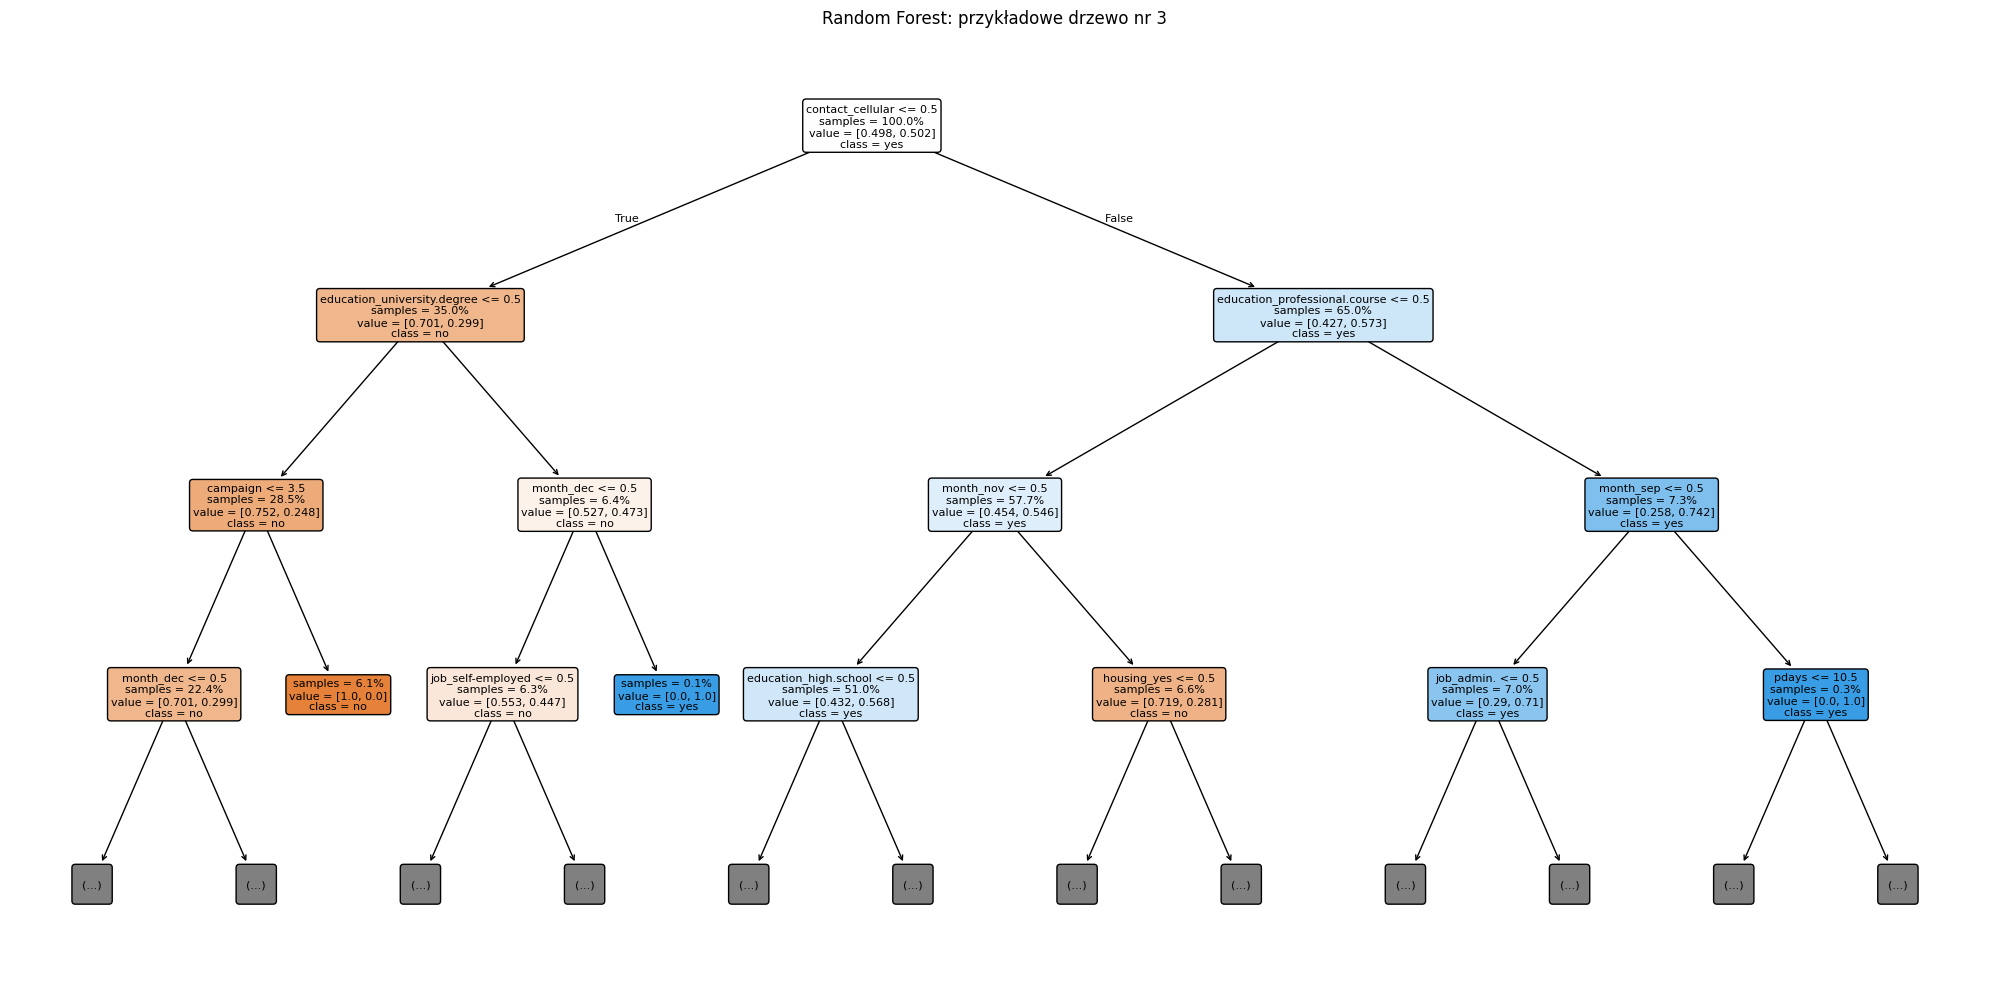

In [11]:
from scripts.explainability import plot_random_forest_tree

TREE_INDEX = 3
plot_random_forest_tree(forest_balanced, tree_index=TREE_INDEX, max_depth=3)

### 3b. Od jakiego pytania zaczynają drzewa?

Pojedyncze drzewo zawsze zaczyna od tego samego pytania. W lesie każde drzewo widzi innych klientów i inne cechy, więc zaczyna od czegoś innego.

In [12]:
from scripts.explainability import forest_first_questions

forest_first_questions(forest_balanced)

,pierwsze pytanie drzewa,liczba drzew
0,contact_cellular,19
1,pdays,13
2,had_previous_contact,10
3,contact_telephone,8
4,month_may,7
5,campaign,7
6,age,6
7,month_mar,6
8,month_sep,4
9,education_professional.course,2


### 3c. Głosowanie dla jednego klienta

Każde drzewo prowadzi klienta do jednego liścia. **Pewność drzewa** to udział klientów `yes` wśród klientów treningowych, którzy trafili do tego samego liścia, np. 30 z 40 daje 0,75. W lesie balanced klienci `yes` liczą się mocniej, bo jest ich mało.

Drzewo z pewnością powyżej 0,5 „głosuje” na `yes`. Las nie liczy jednak głosów, tylko **uśrednia pewności wszystkich drzew**. Jeśli średnia przekracza 0,5, odpowiada `yes`. Dlatego czasem większość drzew mówi „tak”, a las odpowiada „nie”: drzewa na „tak” są tylko trochę pewne, a drzewa na „nie” bardzo pewne. Sprawdźcie np. `ROW_NUMBER = 14`.

Tutaj pojawia się także 'próg' - jednak zmiana go nie jest trywialna, więc na warsztatach nie będziemy go zmieniali.

Rzeczywisty wynik klienta: yes


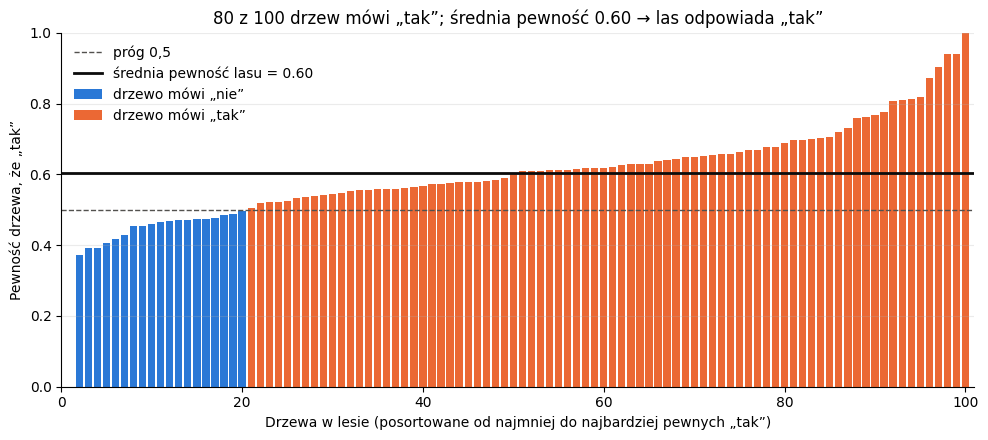

In [13]:
from scripts.explainability import plot_forest_votes

ROW_NUMBER = 0
print(f"Rzeczywisty wynik klienta: {y_test.iloc[ROW_NUMBER]}")
plot_forest_votes(forest_balanced, X_test.iloc[ROW_NUMBER])

## 4. Więcej danych: cały zbiór

Do tej pory pracowaliśmy na 2000 klientach. Teraz wczytujemy **cały zbiór (ponad 41 tys. klientów)** i dzielimy go na trening (80%) i test (20%, ponad 8 tys. klientów). Tak duży test daje dużo stabilniejsze wyniki.

Od tego miejsca używamy lasu `balanced` z sekcji 2b. Wyniki nie są wprost porównywalne z sekcjami 1–3, bo zbiór testowy jest inny.

In [ ]:
df_full, _ = prepare_model_data(n=None, random_state=RANDOM_STATE, data_dir=DATA_DIR)
df_full_for_modelling = preprocess_data(df_full)

X_full = df_full_for_modelling.drop(columns="y")
y_full = df_full_for_modelling["y"]

X_train_full, X_test_full, y_train_full, y_test_full = train_test_split(
    X_full,
    y_full,
    test_size=0.2,
    random_state=SPLIT_SEED,
    stratify=y_full,
)

print(f"Train: {len(X_train_full)} rekordów; test: {len(X_test_full)} rekordów.")

### 4a. Ile danych potrzebuje las?

Zmieniajcie `TRAIN_SIZE` (np. 200, 1600, 5000, 32950) i obserwujcie wyniki. Zbiór testowy cały czas jest ten sam.

In [ ]:
# Zmień TRAIN_SIZE: od 100 do 32950 (cały zbiór treningowy)
TRAIN_SIZE = 1600

forest_full = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=SPLIT_SEED,
    n_jobs=-1,
)

# Bierzemy pierwsze TRAIN_SIZE rekordów treningowych (train_test_split już je wymieszał)
forest_full.fit(X_train_full.iloc[:TRAIN_SIZE], y_train_full.iloc[:TRAIN_SIZE])

y_pred_full = forest_full.predict(X_test_full)
print(f"Trening na {TRAIN_SIZE} rekordach")
print(f"Accuracy: {accuracy_score(y_test_full, y_pred_full):.1%}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test_full, y_pred_full):.1%}")

### 4b. Krzywa uczenia

Jeden trening to trochę loteria: inna próbka 200 klientów da inny wynik. Dlatego dla każdej wielkości zbioru treningowego (100, 300, 1 000, 3 000, 10 000) uczymy las **5 razy** na różnych losowych próbkach, a na koniec raz na całym zbiorze treningowym, czyli razem 26 lasów po 100 drzew. Może to potrwać do pół minuty.

Na wykresie linia pokazuje średni wynik, a pas pokazuje najgorszy i najlepszy z 5 treningów.

**Uwaga:** dla całego zbioru treningowego (32 950) pasa nie ma, bo trening odbywa się tylko raz. Każde losowanie wybrałoby tych samych klientów, więc kolejne treningi dałyby identyczne wyniki. To nie znaczy, że model jest wtedy idealnie stabilny: z innymi klientami w tej samej liczbie wynik też byłby trochę inny.

In [ ]:
from scripts.modeling import run_learning_curve, plot_learning_curve

learning_curve = run_learning_curve(
    RandomForestClassifier(
        n_estimators=100,
        max_depth=6,
        class_weight="balanced",
        random_state=SPLIT_SEED,
        n_jobs=-1,
    ),
    X_train_full,
    y_train_full,
    X_test_full,
    y_test_full,
    repeats=5,
)
plot_learning_curve(learning_curve)

### 4c. Ile drzew w lesie?

Zmieniajcie `N_ESTIMATORS` (np. 1, 10, 100, 300). Dla wybranej liczby drzew uczymy 5 lasów na całym zbiorze treningowym. Lasy różnią się tylko losowością (`random_state`), więc rozrzut wyników pokazuje, jak stabilny jest las. Las z jednym drzewem to w praktyce pojedyncze drzewo.

In [ ]:
# Zmień liczbę drzew w lesie
N_ESTIMATORS = 1

for seed in range(5):
    forest_n = RandomForestClassifier(
        n_estimators=N_ESTIMATORS,
        max_depth=6,
        class_weight="balanced",
        random_state=seed,
        n_jobs=-1,
    )
    forest_n.fit(X_train_full, y_train_full)
    y_pred_n = forest_n.predict(X_test_full)
    print(f"Las nr {seed + 1}: balanced accuracy {balanced_accuracy_score(y_test_full, y_pred_n):.1%}")

## 5. Które cechy są ważne?

Wpiszcie do `FEATURES_TO_DROP` cechy, które chcecie usunąć, np. `["month"]` albo `["pdays", "had_previous_contact"]`. Las uczy się na całym zbiorze treningowym dwa razy: ze wszystkimi cechami i bez wybranych.

Dostępne cechy: `age`, `job`, `education`, `housing`, `contact`, `month`, `campaign`, `pdays`, `had_previous_contact`.

In [ ]:
from scripts.modeling import drop_features

# Wpisz cechy do usunięcia
FEATURES_TO_DROP = ["month"]

X_train_dropped = drop_features(X_train_full, FEATURES_TO_DROP)
X_test_dropped = drop_features(X_test_full, FEATURES_TO_DROP)

forest_all = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=SPLIT_SEED,
    n_jobs=-1,
)
forest_all.fit(X_train_full, y_train_full)
y_pred_all = forest_all.predict(X_test_full)

forest_dropped = RandomForestClassifier(
    n_estimators=100,
    max_depth=6,
    class_weight="balanced",
    random_state=SPLIT_SEED,
    n_jobs=-1,
)
forest_dropped.fit(X_train_dropped, y_train_full)
y_pred_dropped = forest_dropped.predict(X_test_dropped)

pd.DataFrame(
    {
        "accuracy": [
            accuracy_score(y_test_full, y_pred_all),
            accuracy_score(y_test_full, y_pred_dropped),
        ],
        "balanced_accuracy": [
            balanced_accuracy_score(y_test_full, y_pred_all),
            balanced_accuracy_score(y_test_full, y_pred_dropped),
        ],
    },
    index=["wszystkie cechy", f"bez: {', '.join(FEATURES_TO_DROP)}"],
).round(3)

## Pytania do dyskusji

1. Jak accuracy lasu wypada wobec baseline'u „zawsze brak lokaty”? A balanced accuracy?
2. Las `balanced` ma niższą accuracy, ale wyższy recall. Który model wybrałby bank i dlaczego?
3. Czy drzewa w lesie zadają te same pytania? Czy da się wyjaśnić decyzję lasu dla jednego klienta tak łatwo jak decyzję pojedynczego drzewa?
4. Jak zmieniają się accuracy i balanced accuracy na krzywej uczenia, gdy rośnie liczba danych treningowych? Dlaczego accuracy może spadać, choć model coraz lepiej znajduje chętnych?
5. Jak liczba drzew wpływa na wynik i jego stabilność? Czy 300 drzew to dużo lepiej niż 100?
6. Usunięcie których cech najbardziej obniża wynik? Czy są cechy, których usunięcie prawie nic nie zmienia? Dlaczego tak może być?